## Result Summary
This study evaluated whether gene-expression profiles can distinguish Alzheimer's disease (AD) brain samples from normal controls using the GSE48350 hippocampal dataset. The final cohort comprised 44 samples (19 AD, 25 Control). Under a frozen evaluation protocol utilizing 4-fold stratified cross-validation and identical folds, we compared a Dummy baseline, Logistic Regression, Random Forest, and a Calibrated Linear SVM. Logistic Regression, Random Forest, and Calibrated SVM all achieved 97.7% accuracy, 100% sensitivity, and 96% specificity, with Random Forest demonstrating the best probability calibration (Brier: 0.011, ECE: 0.062). Error analysis revealed a single misclassified control sample (GSM300255) across all models. A critical confounding audit exposed that all AD samples belonged to the GSM117 prefix group while all controls belonged to GSM300, raising significant source or cohort confounding concerns that cannot be resolved with the available metadata. Cost-sensitive threshold analysis (FP cost=1, FN cost=5) suggested retaining a 0.50 threshold. While classification performance is highly promising, the small sample size and perfect GSM-prefix association limit clinical validity and highlight the need for external validation.

In [209]:
# DS-A4: Alzheimer’s Disease Gene-Expression Classification

import os
import sys
import gzip
import hashlib
import urllib.request
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn

# Freeze random seed
SEED = 20261104

random.seed(SEED)
np.random.seed(SEED)

# Create project directories
PROJECT_DIR = Path("/content/DS-A4-Alzheimers")

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

for folder in [DATA_DIR, RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Random seed:", SEED)

print("\nPython version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\nProject directories created successfully.")

Project directory: /content/DS-A4-Alzheimers
Random seed: 20261104

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pandas version: 2.2.3
NumPy version: 2.4.6
Scikit-learn version: 1.6.1

Project directories created successfully.


# DS-A4 | Model Comparison and Calibration Lab

## Research Question

Can gene-expression profiles distinguish Alzheimer's disease
(AD) brain samples from normal control samples?

## Dataset

GEO accession: GSE48350  
Organism: Homo sapiens  
Technology: Affymetrix Human Genome U133 Plus 2.0 microarray  
Brain region selected: Hippocampus

## Target

Alzheimer's disease (AD) versus normal control.

## Models

1. Dummy Classifier
2. Logistic Regression
3. Random Forest
4. Support Vector Machine (SVM)

## Main Objectives

- Compare classification performance.
- Evaluate probability calibration.
- Examine false-positive and false-negative errors.
- Identify important gene-expression features.
- Investigate practical classification thresholds.

## Scientific Limitation

This is an exploratory analysis of postmortem brain
gene-expression data. It is not a clinical diagnostic test.

In [210]:
# Download GSE48350 processed Series Matrix

url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE48nnn/GSE48350/matrix/"
    "GSE48350_series_matrix.txt.gz"
)

matrix_path = DATA_DIR / "GSE48350_series_matrix.txt.gz"

urllib.request.urlretrieve(url, matrix_path)

print("Dataset downloaded successfully.")
print("File size:", matrix_path.stat().st_size, "bytes")

# Calculate SHA-256 hash
sha256 = hashlib.sha256()

with open(matrix_path, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(chunk)

matrix_hash = sha256.hexdigest()

print("SHA-256:", matrix_hash)

Dataset downloaded successfully.
File size: 60194969 bytes
SHA-256: 4bb36e0cf50306a96aea853de5f70d5ab63345238997bed8c9b5b290ced58fef


In [211]:
# Inspect GEO sample metadata

with gzip.open(matrix_path, "rt", encoding="utf-8") as f:

    for line in f:

        if line.startswith(
            ("!Sample_title",
             "!Sample_geo_accession",
             "!Sample_characteristics_ch1",
             "!Sample_source_name_ch1",
             "!Sample_platform_id")
        ):

            fields = line.rstrip("\n").split("\t")

            print("\nMetadata field:", fields[0])
            print("Number of samples:", len(fields) - 1)
            print("First five values:")

            for value in fields[1:6]:
                print(" -", value)


Metadata field: !Sample_title
Number of samples: 253
First five values:
 - "PostcentralGyrus_female_91yrs_indiv10"
 - "SuperiorFrontalGyrus_female_91yrs_indiv10"
 - "Hippocampus_female_96yrs_indiv105"
 - "Hippocampus_male_82yrs_indiv106"
 - "Hippocampus_male_84yrs_indiv108"

Metadata field: !Sample_geo_accession
Number of samples: 253
First five values:
 - "GSM300166"
 - "GSM300167"
 - "GSM300168"
 - "GSM300169"
 - "GSM300170"

Metadata field: !Sample_source_name_ch1
Number of samples: 253
First five values:
 - "brain, postcentral gyrus, female, 91 years"
 - "brain, superior frontal gyrus, female, 91 years"
 - "brain, hippocampus, female, 96 years"
 - "brain, hippocampus, male, 82 years"
 - "brain, hippocampus, male, 84 years"

Metadata field: !Sample_characteristics_ch1
Number of samples: 253
First five values:
 - "individual: 10, C"
 - "individual: 10, C"
 - "individual: 105, C"
 - "individual: 106, C"
 - "individual: 108, C"

Metadata field: !Sample_characteristics_ch1
Number of sa

In [212]:
# Parse all sample metadata from the GEO Series Matrix

sample_metadata = {}

with gzip.open(matrix_path, "rt", encoding="utf-8") as f:

    for line in f:

        if line.startswith("!Sample_"):

            fields = line.rstrip("\n").split("\t")
            key = fields[0]

            values = [
                value.strip().strip('"')
                for value in fields[1:]
            ]

            if key not in sample_metadata:
                sample_metadata[key] = values

# Create metadata table
metadata = pd.DataFrame({
    "GSM": sample_metadata["!Sample_geo_accession"],
    "title": sample_metadata["!Sample_title"],
    "source": sample_metadata["!Sample_source_name_ch1"]
})

# Extract repeated characteristics
characteristic_lines = []

with gzip.open(matrix_path, "rt", encoding="utf-8") as f:

    for line in f:

        if line.startswith("!Sample_characteristics_ch1"):
            characteristic_lines.append(
                line.rstrip("\n").split("\t")[1:]
            )

for values in characteristic_lines:

    for i, value in enumerate(values):

        value = value.strip().strip('"')

        if ":" in value:

            key, val = value.split(":", 1)

            key = key.strip().lower()
            val = val.strip()

            if key == "individual":
                metadata.loc[i, "individual_info"] = val

            elif key == "brain region":
                metadata.loc[i, "brain_region"] = val

            elif key == "gender":
                metadata.loc[i, "gender"] = val

            elif key == "age (yrs)":
                metadata.loc[i, "age"] = val

# Inspect metadata
print("Metadata shape:", metadata.shape)

print("\nBrain region counts:")
print(metadata["brain_region"].value_counts(dropna=False))

print("\nIndividual information examples:")
print(metadata["individual_info"].head(10))

print("\nUnique individual information values:")
print(metadata["individual_info"].dropna().unique())

print("\nFirst 10 metadata rows:")
display(metadata.head(10))

Metadata shape: (253, 7)

Brain region counts:
brain_region
superior frontal gyrus    69
hippocampus               62
entorhinal cortex         54
postcentral gyrus         43
post-central gyrus        25
Name: count, dtype: int64

Individual information examples:
0     10, C
1     10, C
2    105, C
3    106, C
4    108, C
5    109, C
6    111, C
7    12, AA
8    12, AA
9    12, AA
Name: individual_info, dtype: object

Unique individual information values:
['10, C' '105, C' '106, C' '108, C' '109, C' '111, C' '12, AA' '14, C'
 '15, C' '16-07, C' '17, C' '18, C' '2, C' '21, C' '26, C' '27, C' '28, C'
 '29, C' '30, C' '34, C' '35, AA' '38, C' '40, C' '40-04, C' '42, C'
 '45, C' '46, C' '47, C' '52, C' '53, C' '54, C' '59, C' '66, C' '67, C'
 '68, C' '71, C' '72, C' '73, C' '76, C' '77, C' '78, C' '79, AA' '8, C'
 '80, AA' '81, AA' '82, AA' '83, C' '84, AA' '85, C' '86, AA' '87, C'
 '88, AA' '93, C' '94, C' '96, C' '98, C' '63, C']

First 10 metadata rows:


,GSM,title,source,individual_info,gender,brain_region,age
0,GSM300166,PostcentralGyrus_female_91yrs_indiv10,"brain, postcentral gyrus, female, 91 years","10, C",female,postcentral gyrus,91
1,GSM300167,SuperiorFrontalGyrus_female_91yrs_indiv10,"brain, superior frontal gyrus, female, 91 years","10, C",female,superior frontal gyrus,91
2,GSM300168,Hippocampus_female_96yrs_indiv105,"brain, hippocampus, female, 96 years","105, C",female,hippocampus,96
3,GSM300169,Hippocampus_male_82yrs_indiv106,"brain, hippocampus, male, 82 years","106, C",male,hippocampus,82
4,GSM300170,Hippocampus_male_84yrs_indiv108,"brain, hippocampus, male, 84 years","108, C",male,hippocampus,84
5,GSM300171,Hippocampus_female_87yrs_indiv109,"brain, hippocampus, female, 87 years","109, C",female,hippocampus,87
6,GSM300172,Hippocampus_female_82yrs_indiv111,"brain, hippocampus, female, 82 years","111, C",female,hippocampus,82
7,GSM300173,EntorhinalCortex_male_45yrs_indiv12,"brain, entorhinal cortex, male, 45 years","12, AA",male,entorhinal cortex,45
8,GSM300174,Hippocampus_male_45yrs_indiv12,"brain, hippocampus, male, 45 years","12, AA",male,hippocampus,45
9,GSM300175,PostcentralGyrus_male_45yrs_indiv12,"brain, postcentral gyrus, male, 45 years","12, AA",male,postcentral gyrus,45


In [213]:
# Identify hippocampus samples and diagnosis labels

metadata["diagnosis"] = metadata["individual_info"].str.extract(
    r",\s*([A-Za-z]+)\s*$"
)

metadata["donor_id"] = metadata["individual_info"].str.extract(
    r"^\s*([^,]+)"
)

hippocampus_metadata = metadata[
    metadata["brain_region"].str.lower().str.contains(
        "hippocampus", na=False
    )
].copy()

print("Hippocampus sample count:", len(hippocampus_metadata))

print("\nDiagnosis counts:")
print(hippocampus_metadata["diagnosis"].value_counts(dropna=False))

print("\nDonor counts by diagnosis:")
print(
    hippocampus_metadata.groupby("diagnosis")["donor_id"]
    .nunique()
)

print("\nHippocampus metadata:")
display(
    hippocampus_metadata[
        ["GSM", "title", "individual_info",
         "donor_id", "diagnosis", "gender", "age"]
    ].head(15)
)

Hippocampus sample count: 62

Diagnosis counts:
diagnosis
C      35
NaN    19
AA      8
Name: count, dtype: int64

Donor counts by diagnosis:
diagnosis
AA     8
C     35
Name: donor_id, dtype: int64

Hippocampus metadata:


,GSM,title,individual_info,donor_id,diagnosis,gender,age
2,GSM300168,Hippocampus_female_96yrs_indiv105,"105, C",105,C,female,96
3,GSM300169,Hippocampus_male_82yrs_indiv106,"106, C",106,C,male,82
4,GSM300170,Hippocampus_male_84yrs_indiv108,"108, C",108,C,male,84
5,GSM300171,Hippocampus_female_87yrs_indiv109,"109, C",109,C,female,87
6,GSM300172,Hippocampus_female_82yrs_indiv111,"111, C",111,C,female,82
8,GSM300174,Hippocampus_male_45yrs_indiv12,"12, AA",12,AA,male,45
12,GSM300178,Hippocampus_male_95yrs_indiv14,"14, C",14,C,male,95
16,GSM300182,Hippocampus_male_80yrs_indiv15,"15, C",15,C,male,80
18,GSM300185,Hippocampus_male_91yrs_indiv16-07,"16-07, C",16-07,C,male,91
20,GSM300187,Hippocampus_female_45yrs_indiv17,"17, C",17,C,female,45


In [214]:
# Correct diagnosis and donor ID extraction

hippocampus_metadata["diagnosis"] = np.where(
    hippocampus_metadata["title"].str.contains(
        r"_AD_", case=False, regex=True
    ),
    "AD",
    np.where(
        hippocampus_metadata["title"].str.contains(
            r"indiv", case=False
        ),
        "Control",
        "Unknown"
    )
)

hippocampus_metadata["donor_id"] = (
    hippocampus_metadata["title"].str.extract(
        r"(?:indiv|_AD_)([\w-]+)",
        expand=False
    )
)

hippocampus_metadata["age"] = pd.to_numeric(
    hippocampus_metadata["age"],
    errors="coerce"
)

print("Corrected diagnosis counts:")
print(hippocampus_metadata["diagnosis"].value_counts())

print("\nSample metadata preview:")
display(
    hippocampus_metadata[
        ["GSM", "title", "donor_id", "diagnosis", "gender", "age"]
    ].head(10)
)

Corrected diagnosis counts:
diagnosis
Control    43
AD         19
Name: count, dtype: int64

Sample metadata preview:


,GSM,title,donor_id,diagnosis,gender,age
2,GSM300168,Hippocampus_female_96yrs_indiv105,105,Control,female,96
3,GSM300169,Hippocampus_male_82yrs_indiv106,106,Control,male,82
4,GSM300170,Hippocampus_male_84yrs_indiv108,108,Control,male,84
5,GSM300171,Hippocampus_female_87yrs_indiv109,109,Control,female,87
6,GSM300172,Hippocampus_female_82yrs_indiv111,111,Control,female,82
8,GSM300174,Hippocampus_male_45yrs_indiv12,12,Control,male,45
12,GSM300178,Hippocampus_male_95yrs_indiv14,14,Control,male,95
16,GSM300182,Hippocampus_male_80yrs_indiv15,15,Control,male,80
18,GSM300185,Hippocampus_male_91yrs_indiv16-07,16-07,Control,male,91
20,GSM300187,Hippocampus_female_45yrs_indiv17,17,Control,female,45


In [215]:
# Correct diagnosis and donor identification

hippocampus_metadata["diagnosis"] = np.where(
    hippocampus_metadata["title"].str.contains(
        r"_AD_", case=False, regex=True
    ),
    "AD",
    np.where(
        hippocampus_metadata["title"].str.contains(
            r"indiv", case=False
        ),
        "Control",
        "Unknown"
    )
)

# Extract donor identifiers from sample titles
hippocampus_metadata["donor_id"] = (
    hippocampus_metadata["title"].str.extract(
        r"(?:indiv|_AD_)([\w-]+)",
        expand=False
    )
)

# Convert age to numeric
hippocampus_metadata["age"] = pd.to_numeric(
    hippocampus_metadata["age"],
    errors="coerce"
)

print("Corrected diagnosis counts:")
print(hippocampus_metadata["diagnosis"].value_counts())

print("\nUnique donors by diagnosis:")
print(
    hippocampus_metadata.groupby("diagnosis")["donor_id"]
    .nunique()
)

print("\nAge summary by diagnosis:")
display(
    hippocampus_metadata.groupby("diagnosis")["age"]
    .agg(["count", "mean", "std", "min", "max"])
)

print("\nDiagnosis and age details:")
display(
    hippocampus_metadata[
        ["GSM", "title", "donor_id", "diagnosis", "age", "gender"]
    ].sort_values(["diagnosis", "age"])
)

Corrected diagnosis counts:
diagnosis
Control    43
AD         19
Name: count, dtype: int64

Unique donors by diagnosis:
diagnosis
AD         19
Control    43
Name: donor_id, dtype: int64

Age summary by diagnosis:


,count,mean,std,min,max
diagnosis,,,,,
AD,19,83.052632,8.475282,60,94
Control,43,62.488372,25.390636,20,99



Diagnosis and age details:


,GSM,title,donor_id,diagnosis,age,gender
188,GSM1176211,hippocampus_female_60_AD_20,20,AD,60,female
189,GSM1176212,hippocampus_female_74_AD_37,37,AD,74,female
190,GSM1176213,hippocampus_female_76_AD_48,48,AD,76,female
198,GSM1176221,hippocampus_male_76_AD_33,33,AD,76,male
199,GSM1176222,hippocampus_male_76_AD_69,69,AD,76,male
...,...,...,...,...,...,...
161,GSM300329,Hippocampus_female_91yrs_indiv94,94,Control,91,female
12,GSM300178,Hippocampus_male_95yrs_indiv14,14,Control,95,male
2,GSM300168,Hippocampus_female_96yrs_indiv105,105,Control,96,female
48,GSM300215,Hippocampus_male_97yrs_indiv34,34,Control,97,male


In [216]:
final_metadata = hippocampus_metadata[
    (hippocampus_metadata["diagnosis"] == "AD") |
    (
        (hippocampus_metadata["diagnosis"] == "Control") &
        (hippocampus_metadata["age"] >= 60)
    )
].copy()

final_metadata = final_metadata.sort_values("GSM")

print("Total samples:", len(final_metadata))
print(final_metadata["diagnosis"].value_counts())

Total samples: 44
diagnosis
Control    25
AD         19
Name: count, dtype: int64


In [217]:
print("Age summary:")
display(
    final_metadata.groupby("diagnosis")["age"].agg(
        ["count", "mean", "std", "min", "max"]
    )
)

print("\nGender distribution:")
display(
    pd.crosstab(
        final_metadata["diagnosis"],
        final_metadata["gender"]
    )
)

Age summary:


,count,mean,std,min,max
diagnosis,,,,,
AD,19,83.052632,8.475282,60,94
Control,25,81.960000,9.993665,64,99



Gender distribution:


gender,female,male
diagnosis,,
AD,10,9
Control,12,13


In [218]:
print("Total selected samples:", len(final_metadata))
print("Unique donor IDs:", final_metadata["donor_id"].nunique())
print("Missing donor IDs:", final_metadata["donor_id"].isna().sum())

print("\nDuplicate donor IDs:")
display(
    final_metadata[
        final_metadata["donor_id"].duplicated(keep=False)
    ][["GSM", "title", "donor_id", "diagnosis", "age", "gender"]]
)

Total selected samples: 44
Unique donor IDs: 43
Missing donor IDs: 0

Duplicate donor IDs:


,GSM,title,donor_id,diagnosis,age,gender
192,GSM1176215,hippocampus_female_86_AD_15,15,AD,86,female
16,GSM300182,Hippocampus_male_80yrs_indiv15,15,Control,80,male


In [219]:
final_metadata["donor_key"] = (
    final_metadata["diagnosis"].astype(str)
    + "_"
    + final_metadata["donor_id"].astype(str)
)

print("Total selected samples:", len(final_metadata))
print("Unique composite donor IDs:", final_metadata["donor_key"].nunique())

print("\nDuplicate composite donor IDs:")
display(
    final_metadata[
        final_metadata["donor_key"].duplicated(keep=False)
    ]
)

Total selected samples: 44
Unique composite donor IDs: 44

Duplicate composite donor IDs:


,GSM,title,source,individual_info,gender,brain_region,age,diagnosis,donor_id,donor_key


In [220]:
metadata_path = DATA_DIR / "GSE48350_selected_metadata.csv"

final_metadata.to_csv(metadata_path, index=False)

print("Selected metadata saved successfully.")
print("File:", metadata_path)
print("Rows:", len(final_metadata))

Selected metadata saved successfully.
File: /content/DS-A4-Alzheimers/data/GSE48350_selected_metadata.csv
Rows: 44


In [221]:
# Confirm the final selected cohort

print("Final selected samples:", len(final_metadata))

print("\nSamples per diagnosis:")
print(final_metadata["diagnosis"].value_counts())

print("\nAge summary:")
display(
    final_metadata.groupby("diagnosis")["age"]
    .agg(["count", "mean", "std", "min", "max"])
)

Final selected samples: 44

Samples per diagnosis:
diagnosis
Control    25
AD         19
Name: count, dtype: int64

Age summary:


,count,mean,std,min,max
diagnosis,,,,,
AD,19,83.052632,8.475282,60,94
Control,25,81.960000,9.993665,64,99


In [222]:
import io
import gzip

with gzip.open(matrix_path, "rt", encoding="utf-8") as f:
    lines = f.readlines()

start = next(
    i for i, line in enumerate(lines)
    if line.startswith("!series_matrix_table_begin")
)

end = next(
    i for i, line in enumerate(lines)
    if line.startswith("!series_matrix_table_end")
)

expression_text = "".join(lines[start + 1:end])

expression = pd.read_csv(
    io.StringIO(expression_text),
    sep="\t"
)

print("Original expression matrix shape:", expression.shape)
display(expression.head())

Original expression matrix shape: (54675, 254)


,ID_REF,GSM300166,GSM300167,GSM300168,GSM300169,GSM300170,GSM300171,GSM300172,GSM300173,GSM300174,...,GSM1176266,GSM1176267,GSM1176268,GSM1176269,GSM1176270,GSM1176271,GSM1176272,GSM1176273,GSM1176274,GSM1176275
0,1007_s_at,0.888016,1.435518,1.609601,1.754960,1.820730,1.439672,1.587641,0.524710,0.796570,...,1.028650,0.774286,1.337073,1.244907,2.087099,0.959862,1.441913,0.904624,0.669172,0.713999
1,1053_at,0.666460,0.885852,1.859078,1.036666,1.421393,1.485035,1.186292,0.876624,0.917716,...,1.044734,0.789405,0.838707,0.825675,1.004600,0.936117,1.000000,0.834758,1.122123,1.202849
2,117_at,0.859638,1.062030,3.097395,2.243655,5.060301,13.800817,2.211287,0.824494,1.650645,...,0.931451,1.903424,1.452228,1.548969,1.064989,0.948225,0.825223,1.081357,1.489901,1.476950
3,121_at,0.975150,1.050745,0.982284,1.198237,1.039529,0.781454,1.011910,1.151515,0.960083,...,0.980565,1.152982,1.000000,0.594645,1.024383,1.140066,0.577931,1.156676,0.861224,1.128132
4,1255_g_at,0.491255,0.537525,3.179645,1.514290,2.185801,3.541644,2.213126,1.422447,5.011413,...,0.560050,0.554573,0.613756,0.521582,0.530901,0.548742,0.458067,0.552341,0.474526,0.559091


In [223]:
# Select expression data for the final 44 samples

selected_gsms = final_metadata["GSM"].tolist()

missing_samples = [
    gsm for gsm in selected_gsms
    if gsm not in expression.columns
]

print("Missing samples:", missing_samples)

expression_selected = expression[
    ["ID_REF"] + selected_gsms
].copy()

for gsm in selected_gsms:
    expression_selected[gsm] = pd.to_numeric(
        expression_selected[gsm],
        errors="coerce"
    )

print("\nSelected expression matrix shape:", expression_selected.shape)

display(expression_selected.head())

Missing samples: []

Selected expression matrix shape: (54675, 45)


,ID_REF,GSM1176211,GSM1176212,GSM1176213,GSM1176214,GSM1176215,GSM1176216,GSM1176217,GSM1176218,GSM1176219,...,GSM300235,GSM300239,GSM300243,GSM300255,GSM300268,GSM300286,GSM300325,GSM300329,GSM300333,GSM300339
0,1007_s_at,1.561895,1.844294,2.647839,1.591138,1.088566,2.230083,1.646972,1.925735,2.255199,...,1.970288,1.482895,2.377805,1.680288,1.410146,1.314789,1.651321,1.696106,1.750857,1.411348
1,1053_at,0.561775,0.880199,0.982979,0.721999,0.910118,0.896981,0.727024,0.873360,0.952196,...,0.712456,1.073326,0.982138,0.633731,0.845724,0.736081,0.635193,0.865832,0.621852,0.885746
2,117_at,2.623355,4.124593,1.811241,1.963337,1.226064,5.979193,3.741925,8.286978,1.872053,...,1.455140,4.066052,1.402324,0.892200,1.708486,1.545587,1.789464,1.840125,1.586228,1.466986
3,121_at,0.978689,0.916411,1.005055,0.832278,1.099983,1.155785,0.867876,1.004200,0.900265,...,0.965454,0.943212,0.853663,0.844299,0.971085,0.997563,1.084734,1.147076,1.148704,0.958179
4,1255_g_at,1.222247,1.020114,0.924377,1.117733,1.165352,0.829035,1.041705,0.817496,0.882860,...,0.945037,1.659933,0.854587,0.728781,1.132950,0.872695,1.621883,0.821431,4.206879,1.478383


In [224]:
# Check expression matrix quality

print("Total probes:", len(expression_selected))

print(
    "Unique probe IDs:",
    expression_selected["ID_REF"].nunique()
)

print(
    "Duplicate probe IDs:",
    expression_selected["ID_REF"].duplicated().sum()
)

numeric_expression = expression_selected.drop(
    columns="ID_REF"
)

print(
    "\nTotal missing values:",
    numeric_expression.isna().sum().sum()
)

print(
    "Total non-finite values:",
    (~np.isfinite(numeric_expression)).sum().sum()
)

print(
    "Zero-variance probes:",
    (numeric_expression.var(axis=1) == 0).sum()
)

print("\nExpression variance summary:")
display(numeric_expression.var(axis=1).describe())

Total probes: 54675
Unique probe IDs: 54675
Duplicate probe IDs: 0

Total missing values: 0
Total non-finite values: 0
Zero-variance probes: 0

Expression variance summary:


,0
count,54675.000000
mean,2.910925
std,210.134248
min,0.000319
25%,0.028348
50%,0.070330
75%,0.176804
max,32057.730793


In [225]:
# Save selected expression matrix

expression_path = DATA_DIR / "GSE48350_selected_expression.csv"

expression_selected.to_csv(
    expression_path,
    index=False
)

print("Selected expression matrix saved successfully.")
print("File:", expression_path)
print("Shape:", expression_selected.shape)

Selected expression matrix saved successfully.
File: /content/DS-A4-Alzheimers/data/GSE48350_selected_expression.csv
Shape: (54675, 45)


In [226]:
# Prepare feature matrix (X) and target labels (y)

X = expression_selected.set_index("ID_REF").T

y = (
    final_metadata
    .set_index("GSM")
    .loc[X.index, "diagnosis"]
    .map({"Control": 0, "AD": 1})
)

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nDiagnosis distribution:")
print(y.value_counts())

print("\nMissing target labels:", y.isna().sum())

display(X.head())

Feature matrix shape: (44, 54675)
Target vector shape: (44,)

Diagnosis distribution:
diagnosis
0    25
1    19
Name: count, dtype: int64

Missing target labels: 0


ID_REF,1007_s_at,1053_at,117_at,121_at,1255_g_at,1294_at,1316_at,1320_at,1405_i_at,1431_at,...,AFFX-r2-Ec-bioD-3_at,AFFX-r2-Ec-bioD-5_at,AFFX-r2-P1-cre-3_at,AFFX-r2-P1-cre-5_at,AFFX-ThrX-3_at,AFFX-ThrX-5_at,AFFX-ThrX-M_at,AFFX-TrpnX-3_at,AFFX-TrpnX-5_at,AFFX-TrpnX-M_at
GSM1176211,1.561895,0.561775,2.623355,0.978689,1.222247,0.942119,0.809320,1.332006,1.193066,0.540340,...,0.871052,0.857145,1.015643,0.882810,0.442347,0.615870,0.421658,0.747214,0.493243,0.622503
GSM1176212,1.844294,0.880199,4.124593,0.916411,1.020114,2.249897,0.721445,1.358980,1.406844,0.516278,...,1.206120,1.204373,1.138296,1.005751,2.735287,4.532946,4.174031,0.748078,0.505133,0.643565
GSM1176213,2.647839,0.982979,1.811241,1.005055,0.924377,2.629780,0.605610,3.008573,1.694976,0.817771,...,0.699747,0.707242,0.849897,0.812087,1.362179,1.323929,1.448986,0.683487,0.475607,0.610981
GSM1176214,1.591138,0.721999,1.963337,0.832278,1.117733,1.098982,0.881586,1.908031,0.807429,0.724896,...,1.165965,1.281644,1.074282,1.028626,1.435100,1.691617,1.684754,0.620698,0.420378,0.524897
GSM1176215,1.088566,0.910118,1.226064,1.099983,1.165352,1.201150,0.885712,1.338069,1.118838,1.052228,...,1.157843,1.085196,1.071253,1.073354,1.245477,2.372587,1.875951,0.800364,0.536113,0.726125


In [227]:
# Check sample alignment

print("X sample order matches y:", X.index.equals(y.index))

print(
    "X sample order matches metadata:",
    X.index.equals(final_metadata.set_index("GSM").loc[X.index].index)
)

print("\nFirst five sample IDs:")
print(X.index[:5].tolist())

print("\nFirst five target labels:")
print(y.head().tolist())

X sample order matches y: True
X sample order matches metadata: True

First five sample IDs:
['GSM1176211', 'GSM1176212', 'GSM1176213', 'GSM1176214', 'GSM1176215']

First five target labels:
[1, 1, 1, 1, 1]


In [228]:
# Create stratified 4-fold cross-validation

from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=SEED
)

fold_assignments = pd.Series(
    index=X.index,
    dtype="int64",
    name="fold"
)

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y),
    start=1
):
    fold_assignments.iloc[test_idx] = fold

    print(f"\nFold {fold}")
    print("Training samples:", len(train_idx))
    print("Testing samples:", len(test_idx))

    print("Training classes:")
    print(y.iloc[train_idx].value_counts().sort_index().to_dict())

    print("Testing classes:")
    print(y.iloc[test_idx].value_counts().sort_index().to_dict())

print("\nFold assignment counts:")
print(fold_assignments.value_counts().sort_index())


Fold 1
Training samples: 33
Testing samples: 11
Training classes:
{0: 19, 1: 14}
Testing classes:
{0: 6, 1: 5}

Fold 2
Training samples: 33
Testing samples: 11
Training classes:
{0: 19, 1: 14}
Testing classes:
{0: 6, 1: 5}

Fold 3
Training samples: 33
Testing samples: 11
Training classes:
{0: 19, 1: 14}
Testing classes:
{0: 6, 1: 5}

Fold 4
Training samples: 33
Testing samples: 11
Training classes:
{0: 18, 1: 15}
Testing classes:
{0: 7, 1: 4}

Fold assignment counts:
fold
1.0    11
2.0    11
3.0    11
4.0    11
Name: count, dtype: int64


In [229]:
# Save cross-validation fold assignments

fold_path = RESULTS_DIR / "fold_assignments.csv"

fold_assignments.rename_axis("GSM").reset_index().to_csv(
    fold_path,
    index=False
)

print("Fold assignments saved successfully.")
print("File:", fold_path)
print("Total samples:", len(fold_assignments))
print("Unique folds:", fold_assignments.nunique())

Fold assignments saved successfully.
File: /content/DS-A4-Alzheimers/results/fold_assignments.csv
Total samples: 44
Unique folds: 4


In [230]:
# Prepare machine-learning models

from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import Pipeline

from sklearn.base import clone

K_FEATURES = 50

# 1. Dummy Classifier
dummy_model = DummyClassifier(
    strategy="prior"
)

# 2. Logistic Regression
logistic_model = Pipeline([
    ("feature_selection", SelectKBest(score_func=f_classif, k=K_FEATURES)),
    ("scaling", StandardScaler()),
    ("classifier", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=5000,
        random_state=SEED
    ))
])

# 3. Random Forest
rf_model = Pipeline([
    ("feature_selection", SelectKBest(score_func=f_classif, k=K_FEATURES)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    ))
])

# 4. Calibrated Linear SVM
svm_pipeline = Pipeline([
    ("feature_selection", SelectKBest(score_func=f_classif, k=K_FEATURES)),
    ("scaling", StandardScaler()),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=SEED,
        max_iter=10000
    ))
])

svm_model = CalibratedClassifierCV(
    estimator=svm_pipeline,
    method="sigmoid",
    cv=3
)

models = {
    "Dummy": dummy_model,
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "Calibrated Linear SVM": svm_model
}

print("Models prepared:")
for model_name in models:
    print("-", model_name)

print("\nFeature selection:", K_FEATURES, "probes")
print("Outer evaluation: 4-fold stratified cross-validation")
print("SVM probability calibration: 3-fold sigmoid calibration")

Models prepared:
- Dummy
- Logistic Regression
- Random Forest
- Calibrated Linear SVM

Feature selection: 50 probes
Outer evaluation: 4-fold stratified cross-validation
SVM probability calibration: 3-fold sigmoid calibration


In [231]:
# Generate out-of-fold predictions

from sklearn.metrics import accuracy_score

oof_predictions = pd.DataFrame(
    index=X.index
)

oof_predictions["y_true"] = y

for model_name, model in models.items():

    print(f"\nRunning model: {model_name}")

    probabilities = pd.Series(
        index=X.index,
        dtype=float
    )

    for fold, (train_idx, test_idx) in enumerate(
        cv.split(X, y),
        start=1
    ):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]

        fitted_model = clone(model)

        fitted_model.fit(X_train, y_train)

        fold_probabilities = fitted_model.predict_proba(
            X_test
        )[:, 1]

        probabilities.iloc[test_idx] = fold_probabilities

        print(f"Fold {fold} completed.")

    oof_predictions[model_name] = probabilities

print("\nAll model predictions generated successfully.")

display(oof_predictions.head())


Running model: Dummy
Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.

Running model: Logistic Regression
Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.

Running model: Random Forest
Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.

Running model: Calibrated Linear SVM
Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.

All model predictions generated successfully.


,y_true,Dummy,Logistic Regression,Random Forest,Calibrated Linear SVM
GSM1176211,1,0.424242,0.943954,0.907206,0.672343
GSM1176212,1,0.424242,0.994088,0.913333,0.721943
GSM1176213,1,0.424242,0.991190,0.924389,0.632894
GSM1176214,1,0.424242,0.945070,0.798586,0.637411
GSM1176215,1,0.424242,0.985493,0.965253,0.697361


In [232]:
# Save out-of-fold predictions

oof_path = RESULTS_DIR / "oof_predictions.csv"

oof_predictions.to_csv(oof_path, index=True)

print("OOF predictions saved successfully:")
print(oof_path)

print("\nPrediction dataset shape:", oof_predictions.shape)
print("Missing predictions:")
display(oof_predictions.isna().sum())

OOF predictions saved successfully:
/content/DS-A4-Alzheimers/results/oof_predictions.csv

Prediction dataset shape: (44, 5)
Missing predictions:


,0
y_true,0
Dummy,0
Logistic Regression,0
Random Forest,0
Calibrated Linear SVM,0


In [233]:
# Calculate classification performance

from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

THRESHOLD = 0.5

classification_results = []

for model_name in models.keys():

    y_true = oof_predictions["y_true"]

    y_pred = (
        oof_predictions[model_name] >= THRESHOLD
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    classification_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Sensitivity": recall_score(y_true, y_pred),
        "Specificity": tn / (tn + fp),
        "Precision": precision_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred)
    })

classification_results = pd.DataFrame(
    classification_results
)

display(
    classification_results.round(3)
)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Model,Accuracy,Sensitivity,Specificity,Precision,F1-score,Balanced Accuracy
0,Dummy,0.568,0.0,1.00,0.00,0.000,0.50
1,Logistic Regression,0.977,1.0,0.96,0.95,0.974,0.98
2,Random Forest,0.977,1.0,0.96,0.95,0.974,0.98
3,Calibrated Linear SVM,0.977,1.0,0.96,0.95,0.974,0.98


In [234]:
# Calculate probability-based performance

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

probability_results = []

for model_name in models.keys():

    y_true = oof_predictions["y_true"]
    y_prob = oof_predictions[model_name]

    probability_results.append({
        "Model": model_name,
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
        "Brier Score": brier_score_loss(y_true, y_prob),
        "Log Loss": log_loss(y_true, y_prob, labels=[0, 1])
    })

probability_results = pd.DataFrame(
    probability_results
)

display(
    probability_results.round(4)
)

,Model,ROC-AUC,PR-AUC,Brier Score,Log Loss
0,Dummy,0.4653,0.4175,0.2466,0.6863
1,Logistic Regression,0.9600,0.8633,0.0239,0.3351
2,Random Forest,1.0000,1.0000,0.0110,0.0697
3,Calibrated Linear SVM,0.9663,0.9203,0.0945,0.3573


In [235]:
# Evaluate probability calibration using fixed-width bins

calibration_bins = np.linspace(0, 1, 6)

calibration_tables = {}
ece_results = []

for model_name in models.keys():

    temp = pd.DataFrame({
        "y_true": oof_predictions["y_true"],
        "y_prob": oof_predictions[model_name]
    })

    temp["probability_bin"] = pd.cut(
        temp["y_prob"],
        bins=calibration_bins,
        include_lowest=True
    )

    calibration_table = (
        temp.groupby("probability_bin", observed=False)
        .agg(
            sample_count=("y_true", "count"),
            mean_predicted_probability=("y_prob", "mean"),
            observed_AD_fraction=("y_true", "mean")
        )
        .dropna()
    )

    ece = (
        calibration_table["sample_count"]
        / len(temp)
        * abs(
            calibration_table["mean_predicted_probability"]
            - calibration_table["observed_AD_fraction"]
        )
    ).sum()

    calibration_tables[model_name] = calibration_table

    ece_results.append({
        "Model": model_name,
        "ECE": ece
    })

    print(f"\n{model_name}")
    display(calibration_table.round(3))

ece_results = pd.DataFrame(ece_results)

print("\nExpected Calibration Error (ECE):")
display(ece_results.round(4))


Dummy


,sample_count,mean_predicted_probability,observed_AD_fraction
probability_bin,,,
"(0.4, 0.6]",44,0.432,0.432



Logistic Regression


,sample_count,mean_predicted_probability,observed_AD_fraction
probability_bin,,,
"(-0.001, 0.2]",24,0.021,0.00
"(0.8, 1.0]",20,0.984,0.95



Random Forest


,sample_count,mean_predicted_probability,observed_AD_fraction
probability_bin,,,
"(-0.001, 0.2]",23,0.036,0.0
"(0.2, 0.4]",1,0.207,0.0
"(0.4, 0.6]",1,0.513,0.0
"(0.6, 0.8]",1,0.799,1.0
"(0.8, 1.0]",18,0.945,1.0



Calibrated Linear SVM


,sample_count,mean_predicted_probability,observed_AD_fraction
probability_bin,,,
"(-0.001, 0.2]",5,0.163,0.000
"(0.2, 0.4]",18,0.281,0.000
"(0.4, 0.6]",1,0.433,0.000
"(0.6, 0.8]",18,0.697,0.944
"(0.8, 1.0]",2,0.817,1.000



Expected Calibration Error (ECE):


,Model,ECE
0,Dummy,0.0000
1,Logistic Regression,0.0270
2,Random Forest,0.0622
3,Calibrated Linear SVM,0.2532


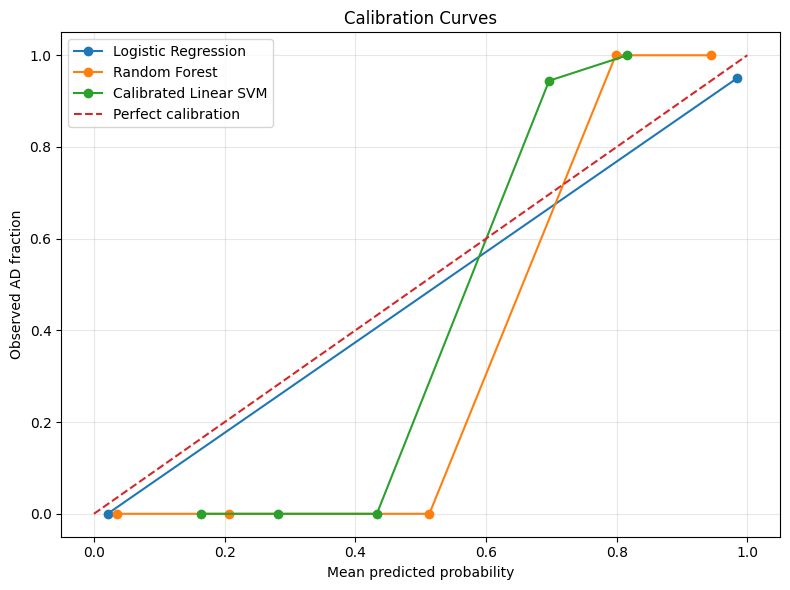

Calibration plot saved:
/content/DS-A4-Alzheimers/results/figures/calibration_curves.png


In [236]:
# Plot calibration curves

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

plt.figure(figsize=(8, 6))

for model_name in [
    "Logistic Regression",
    "Random Forest",
    "Calibrated Linear SVM"
]:

    y_true = oof_predictions["y_true"]
    y_prob = oof_predictions[model_name]

    observed_fraction, mean_predicted = calibration_curve(
        y_true,
        y_prob,
        n_bins=5,
        strategy="uniform"
    )

    plt.plot(
        mean_predicted,
        observed_fraction,
        marker="o",
        label=model_name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed AD fraction")
plt.title("Calibration Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

calibration_plot_path = FIGURES_DIR / "calibration_curves.png"

plt.savefig(
    calibration_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Calibration plot saved:")
print(calibration_plot_path)

In [237]:
# Compare classification performance at different thresholds

thresholds = [0.3, 0.5, 0.7]

threshold_results = []

for model_name in [
    "Logistic Regression",
    "Random Forest",
    "Calibrated Linear SVM"
]:

    y_true = oof_predictions["y_true"]
    y_prob = oof_predictions[model_name]

    for threshold in thresholds:

        y_pred = (y_prob >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        ).ravel()

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "TP": tp,
            "FP": fp,
            "TN": tn,
            "FN": fn,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Sensitivity": recall_score(y_true, y_pred),
            "Specificity": tn / (tn + fp)
        })

threshold_results = pd.DataFrame(threshold_results)

display(threshold_results.round(3))

,Model,Threshold,TP,FP,TN,FN,Accuracy,Sensitivity,Specificity
0,Logistic Regression,0.3,19,1,24,0,0.977,1.000,0.96
1,Logistic Regression,0.5,19,1,24,0,0.977,1.000,0.96
2,Logistic Regression,0.7,19,1,24,0,0.977,1.000,0.96
3,Random Forest,0.3,19,1,24,0,0.977,1.000,0.96
4,Random Forest,0.5,19,1,24,0,0.977,1.000,0.96
5,Random Forest,0.7,19,0,25,0,1.000,1.000,1.00
6,Calibrated Linear SVM,0.3,19,8,17,0,0.818,1.000,0.68
7,Calibrated Linear SVM,0.5,19,1,24,0,0.977,1.000,0.96
8,Calibrated Linear SVM,0.7,8,1,24,11,0.727,0.421,0.96


In [238]:
# Identify incorrectly classified samples at threshold 0.5

ERROR_THRESHOLD = 0.5

for model_name in [
    "Logistic Regression",
    "Random Forest",
    "Calibrated Linear SVM"
]:

    y_true = oof_predictions["y_true"]

    y_pred = (
        oof_predictions[model_name] >= ERROR_THRESHOLD
    ).astype(int)

    error_mask = y_true != y_pred

    error_samples = pd.DataFrame({
        "Actual diagnosis": y_true[error_mask],
        "Predicted probability": oof_predictions.loc[
            error_mask, model_name
        ],
        "Predicted diagnosis": y_pred[error_mask]
    })

    print(f"\n{model_name}")
    print("Number of errors:", error_mask.sum())

    display(error_samples)


Logistic Regression
Number of errors: 1


,Actual diagnosis,Predicted probability,Predicted diagnosis
GSM300255,0,0.999999,1



Random Forest
Number of errors: 1


,Actual diagnosis,Predicted probability,Predicted diagnosis
GSM300255,0,0.513333,1



Calibrated Linear SVM
Number of errors: 1


,Actual diagnosis,Predicted probability,Predicted diagnosis
GSM300255,0,0.782536,1


In [239]:
# Investigate the commonly misclassified sample

sample_id = "GSM300255"

sample_info = (
    final_metadata
    .set_index("GSM")
    .loc[[sample_id]]
)

print("Metadata for misclassified sample:")
display(sample_info.T)

print("\nPredicted probabilities from all models:")
display(
    oof_predictions.loc[
        [sample_id]
    ].T
)

Metadata for misclassified sample:


GSM,GSM300255
title,Hippocampus_male_69yrs_indiv67
source,"brain, hippocampus, male, 69 years"
individual_info,"67, C"
gender,male
brain_region,hippocampus
age,69
diagnosis,Control
donor_id,67
donor_key,Control_67



Predicted probabilities from all models:


,GSM300255
y_true,0.000000
Dummy,0.424242
Logistic Regression,0.999999
Random Forest,0.513333
Calibrated Linear SVM,0.782536


In [240]:
# Compare prediction agreement between models

from itertools import combinations

model_names = [
    "Logistic Regression",
    "Random Forest",
    "Calibrated Linear SVM"
]

binary_predictions = pd.DataFrame(index=oof_predictions.index)

for model_name in model_names:
    binary_predictions[model_name] = (
        oof_predictions[model_name] >= 0.5
    ).astype(int)

print("Prediction agreement between models:")

for model_a, model_b in combinations(model_names, 2):

    agreement = (
        binary_predictions[model_a]
        == binary_predictions[model_b]
    ).sum()

    print(
        f"{model_a} vs {model_b}: "
        f"{agreement}/44 samples agree"
    )

print("\nPrediction counts:")
display(binary_predictions.sum().to_frame("Predicted AD samples"))

Prediction agreement between models:
Logistic Regression vs Random Forest: 44/44 samples agree
Logistic Regression vs Calibrated Linear SVM: 44/44 samples agree
Random Forest vs Calibrated Linear SVM: 44/44 samples agree

Prediction counts:


,Predicted AD samples
Logistic Regression,20
Random Forest,20
Calibrated Linear SVM,20


In [241]:
# Pairwise McNemar tests

from itertools import combinations
from statsmodels.stats.contingency_tables import mcnemar

mcnemar_results = []

for model_a, model_b in combinations(model_names, 2):

    correct_a = (
        binary_predictions[model_a]
        == oof_predictions["y_true"]
    )

    correct_b = (
        binary_predictions[model_b]
        == oof_predictions["y_true"]
    )

    both_correct = (correct_a & correct_b).sum()
    a_correct_b_wrong = (correct_a & ~correct_b).sum()
    a_wrong_b_correct = (~correct_a & correct_b).sum()
    both_wrong = (~correct_a & ~correct_b).sum()

    contingency_table = [
        [both_correct, a_correct_b_wrong],
        [a_wrong_b_correct, both_wrong]
    ]

    test_result = mcnemar(
        contingency_table,
        exact=True
    )

    mcnemar_results.append({
        "Model A": model_a,
        "Model B": model_b,
        "A correct, B wrong": a_correct_b_wrong,
        "A wrong, B correct": a_wrong_b_correct,
        "McNemar p-value": test_result.pvalue
    })

mcnemar_results = pd.DataFrame(mcnemar_results)

display(mcnemar_results.round(4))

,Model A,Model B,"A correct, B wrong","A wrong, B correct",McNemar p-value
0,Logistic Regression,Random Forest,0,0,1.0
1,Logistic Regression,Calibrated Linear SVM,0,0,1.0
2,Random Forest,Calibrated Linear SVM,0,0,1.0


In [242]:
# Paired bootstrap comparison of ROC-AUC and Brier score

from sklearn.metrics import roc_auc_score, brier_score_loss

N_BOOTSTRAP = 2000
rng = np.random.default_rng(SEED)

comparison_pairs = list(combinations(model_names, 2))

bootstrap_results = []

y_true = oof_predictions["y_true"].to_numpy()

for model_a, model_b in comparison_pairs:

    prob_a = oof_predictions[model_a].to_numpy()
    prob_b = oof_predictions[model_b].to_numpy()

    auc_differences = []
    brier_differences = []

    for _ in range(N_BOOTSTRAP):

        indices = rng.choice(
            len(y_true),
            size=len(y_true),
            replace=True
        )

        y_boot = y_true[indices]

        if len(np.unique(y_boot)) < 2:
            continue

        auc_a = roc_auc_score(
            y_boot, prob_a[indices]
        )

        auc_b = roc_auc_score(
            y_boot, prob_b[indices]
        )

        brier_a = brier_score_loss(
            y_boot, prob_a[indices]
        )

        brier_b = brier_score_loss(
            y_boot, prob_b[indices]
        )

        auc_differences.append(auc_a - auc_b)
        brier_differences.append(brier_a - brier_b)

    bootstrap_results.append({
        "Model A": model_a,
        "Model B": model_b,
        "AUC difference (A-B)": np.mean(auc_differences),
        "AUC CI lower": np.percentile(auc_differences, 2.5),
        "AUC CI upper": np.percentile(auc_differences, 97.5),
        "Brier difference (A-B)": np.mean(brier_differences),
        "Brier CI lower": np.percentile(brier_differences, 2.5),
        "Brier CI upper": np.percentile(brier_differences, 97.5)
    })

bootstrap_results = pd.DataFrame(bootstrap_results)

display(bootstrap_results.round(4))

,Model A,Model B,AUC difference (A-B),AUC CI lower,AUC CI upper,Brier difference (A-B),Brier CI lower,Brier CI upper
0,Logistic Regression,Random Forest,-0.0403,-0.1304,0.0000,0.0133,-0.0062,0.0481
1,Logistic Regression,Calibrated Linear SVM,-0.0062,-0.0253,0.0000,-0.0703,-0.0913,-0.0445
2,Random Forest,Calibrated Linear SVM,0.0331,0.0000,0.1111,-0.0836,-0.1011,-0.0690


In [243]:
# Save paired bootstrap comparison results

bootstrap_path = RESULTS_DIR / "paired_bootstrap_comparisons.csv"

bootstrap_results.to_csv(
    bootstrap_path,
    index=False
)

print("Paired bootstrap results saved to:", bootstrap_path)
print("Number of pairwise comparisons:", len(bootstrap_results))

Paired bootstrap results saved to: /content/DS-A4-Alzheimers/results/paired_bootstrap_comparisons.csv
Number of pairwise comparisons: 3


In [244]:
# Combine classification and probability performance metrics

performance_summary = classification_results.merge(
    probability_results,
    on="Model"
)

print("Combined model performance summary:")
display(performance_summary.round(4))

Combined model performance summary:


,Model,Accuracy,Sensitivity,Specificity,Precision,F1-score,Balanced Accuracy,ROC-AUC,PR-AUC,Brier Score,Log Loss
0,Dummy,0.5682,0.0,1.00,0.00,0.0000,0.50,0.4653,0.4175,0.2466,0.6863
1,Logistic Regression,0.9773,1.0,0.96,0.95,0.9744,0.98,0.9600,0.8633,0.0239,0.3351
2,Random Forest,0.9773,1.0,0.96,0.95,0.9744,0.98,1.0000,1.0000,0.0110,0.0697
3,Calibrated Linear SVM,0.9773,1.0,0.96,0.95,0.9744,0.98,0.9663,0.9203,0.0945,0.3573


In [245]:
# Save combined model performance summary

performance_path = RESULTS_DIR / "combined_model_performance.csv"

performance_summary.to_csv(
    performance_path,
    index=False
)

print("Combined performance results saved to:", performance_path)
print("Number of models:", len(performance_summary))
print("Number of performance metrics:", len(performance_summary.columns) - 1)

Combined performance results saved to: /content/DS-A4-Alzheimers/results/combined_model_performance.csv
Number of models: 4
Number of performance metrics: 10


In [246]:
# Performance by diagnosis group

from sklearn.metrics import recall_score

subgroup_results = []

for model_name in model_names:

    y_true = oof_predictions["y_true"]
    y_pred = (
        oof_predictions[model_name] >= 0.5
    ).astype(int)

    for group, label in [("Control", 0), ("AD", 1)]:

        mask = y_true == label

        correct = (
            y_pred[mask] == y_true[mask]
        ).sum()

        total = mask.sum()

        subgroup_results.append({
            "Model": model_name,
            "Diagnosis": group,
            "Correct": correct,
            "Total": total,
            "Accuracy": correct / total
        })

subgroup_results = pd.DataFrame(subgroup_results)

print("Model performance by diagnosis group:")
display(subgroup_results.round(4))

Model performance by diagnosis group:


,Model,Diagnosis,Correct,Total,Accuracy
0,Logistic Regression,Control,24,25,0.96
1,Logistic Regression,AD,19,19,1.00
2,Random Forest,Control,24,25,0.96
3,Random Forest,AD,19,19,1.00
4,Calibrated Linear SVM,Control,24,25,0.96
5,Calibrated Linear SVM,AD,19,19,1.00


In [247]:
# Save subgroup performance results

subgroup_path = RESULTS_DIR / "subgroup_performance.csv"

subgroup_results.to_csv(
    subgroup_path,
    index=False
)

print("Subgroup results saved to:", subgroup_path)
print("Number of subgroup comparisons:", len(subgroup_results))

Subgroup results saved to: /content/DS-A4-Alzheimers/results/subgroup_performance.csv
Number of subgroup comparisons: 6


In [248]:
# Model performance by age group

age_metadata = final_metadata.set_index("GSM").loc[
    oof_predictions.index
]

age_groups = pd.Series(
    np.where(age_metadata["age"] < 80, "<80 years", "80+ years"),
    index=age_metadata.index,
    name="Age group"
)

age_results = []

for model_name in model_names:

    y_true = oof_predictions["y_true"]
    y_pred = (
        oof_predictions[model_name] >= 0.5
    ).astype(int)

    for group in ["<80 years", "80+ years"]:

        mask = age_groups == group

        correct = (
            y_pred[mask] == y_true[mask]
        ).sum()

        total = mask.sum()

        age_results.append({
            "Model": model_name,
            "Age group": group,
            "Correct": correct,
            "Total": total,
            "Accuracy": correct / total if total > 0 else np.nan
        })

age_results = pd.DataFrame(age_results)

print("Model performance by age group:")
display(age_results.round(4))

print("\nSample counts by age group:")
display(age_groups.value_counts().to_frame("Number of samples"))

Model performance by age group:


,Model,Age group,Correct,Total,Accuracy
0,Logistic Regression,<80 years,15,16,0.9375
1,Logistic Regression,80+ years,28,28,1.0000
2,Random Forest,<80 years,15,16,0.9375
3,Random Forest,80+ years,28,28,1.0000
4,Calibrated Linear SVM,<80 years,15,16,0.9375
5,Calibrated Linear SVM,80+ years,28,28,1.0000



Sample counts by age group:


,Number of samples
Age group,
80+ years,28
<80 years,16


In [249]:
# Save age-group performance results

age_path = RESULTS_DIR / "age_group_performance.csv"

age_results.to_csv(
    age_path,
    index=False
)

print("Age-group results saved to:", age_path)
print("Number of comparisons:", len(age_results))
print("Number of age groups:", age_results["Age group"].nunique())

Age-group results saved to: /content/DS-A4-Alzheimers/results/age_group_performance.csv
Number of comparisons: 6
Number of age groups: 2


In [250]:
# Model performance by gender

gender_metadata = final_metadata.set_index("GSM").loc[
    oof_predictions.index
]

gender_results = []

for model_name in model_names:

    y_true = oof_predictions["y_true"]
    y_pred = (
        oof_predictions[model_name] >= 0.5
    ).astype(int)

    for gender in ["male", "female"]:

        mask = (
            gender_metadata["gender"].str.lower() == gender
        )

        correct = (
            y_pred[mask] == y_true[mask]
        ).sum()

        total = mask.sum()

        gender_results.append({
            "Model": model_name,
            "Gender": gender.capitalize(),
            "Correct": correct,
            "Total": total,
            "Accuracy": correct / total if total > 0 else np.nan
        })

gender_results = pd.DataFrame(gender_results)

print("Model performance by gender:")
display(gender_results.round(4))

print("\nSample counts by gender:")
display(
    gender_metadata["gender"]
    .value_counts()
    .to_frame("Number of samples")
)

Model performance by gender:


,Model,Gender,Correct,Total,Accuracy
0,Logistic Regression,Male,21,22,0.9545
1,Logistic Regression,Female,22,22,1.0000
2,Random Forest,Male,21,22,0.9545
3,Random Forest,Female,22,22,1.0000
4,Calibrated Linear SVM,Male,21,22,0.9545
5,Calibrated Linear SVM,Female,22,22,1.0000



Sample counts by gender:


,Number of samples
gender,
female,22
male,22


In [251]:
# Save gender-group performance results

gender_path = RESULTS_DIR / "gender_group_performance.csv"

gender_results.to_csv(
    gender_path,
    index=False
)

print("Gender-group results saved to:", gender_path)
print("Number of comparisons:", len(gender_results))
print("Number of gender groups:", gender_results["Gender"].nunique())

Gender-group results saved to: /content/DS-A4-Alzheimers/results/gender_group_performance.csv
Number of comparisons: 6
Number of gender groups: 2


In [252]:
# Identify misclassified samples across all models

error_details = []

for model_name in model_names:

    y_true = oof_predictions["y_true"]

    y_pred = (
        oof_predictions[model_name] >= 0.5
    ).astype(int)

    error_indices = oof_predictions.index[
        y_true != y_pred
    ]

    for gsm in error_indices:

        sample_info = final_metadata[
            final_metadata["GSM"] == gsm
        ].iloc[0]

        error_details.append({
            "Model": model_name,
            "GSM": gsm,
            "Actual diagnosis": "AD" if y_true.loc[gsm] == 1 else "Control",
            "Predicted diagnosis": "AD" if y_pred.loc[gsm] == 1 else "Control",
            "Age": sample_info["age"],
            "Gender": sample_info["gender"],
            "Brain region": sample_info["brain_region"]
        })

error_details = pd.DataFrame(error_details)

print("Misclassified samples across models:")
display(error_details)

print("\nNumber of errors per model:")
display(
    error_details.groupby("Model")["GSM"]
    .count()
    .to_frame("Number of errors")
)

Misclassified samples across models:


,Model,GSM,Actual diagnosis,Predicted diagnosis,Age,Gender,Brain region
0,Logistic Regression,GSM300255,Control,AD,69,male,hippocampus
1,Random Forest,GSM300255,Control,AD,69,male,hippocampus
2,Calibrated Linear SVM,GSM300255,Control,AD,69,male,hippocampus



Number of errors per model:


,Number of errors
Model,
Calibrated Linear SVM,1
Logistic Regression,1
Random Forest,1


In [253]:
# Save misclassification details

error_path = RESULTS_DIR / "misclassified_samples.csv"

error_details.to_csv(
    error_path,
    index=False
)

print("Misclassification details saved to:", error_path)
print("Total error records:", len(error_details))
print("Unique misclassified samples:", error_details["GSM"].nunique())

Misclassification details saved to: /content/DS-A4-Alzheimers/results/misclassified_samples.csv
Total error records: 3
Unique misclassified samples: 1


In [254]:
# Inspect available metadata columns

print("Available columns in final_metadata:")
print(final_metadata.columns.tolist())

print("\nFirst five metadata records:")
display(final_metadata.head())

Available columns in final_metadata:
['GSM', 'title', 'source', 'individual_info', 'gender', 'brain_region', 'age', 'diagnosis', 'donor_id', 'donor_key']

First five metadata records:


,GSM,title,source,individual_info,gender,brain_region,age,diagnosis,donor_id,donor_key
188,GSM1176211,hippocampus_female_60_AD_20,hippocampus_female_AD,NaN,female,hippocampus,60,AD,20,AD_20
189,GSM1176212,hippocampus_female_74_AD_37,hippocampus_female_AD,NaN,female,hippocampus,74,AD,37,AD_37
190,GSM1176213,hippocampus_female_76_AD_48,hippocampus_female_AD,NaN,female,hippocampus,76,AD,48,AD_48
191,GSM1176214,hippocampus_female_79_AD_16,hippocampus_female_AD,NaN,female,hippocampus,79,AD,16,AD_16
192,GSM1176215,hippocampus_female_86_AD_15,hippocampus_female_AD,NaN,female,hippocampus,86,AD,15,AD_15


In [255]:
# Inspect source information by diagnosis

print("Source distribution by diagnosis:")
display(
    pd.crosstab(
        final_metadata["source"],
        final_metadata["diagnosis"],
        margins=True
    )
)

print("\nGSM prefix distribution by diagnosis:")
final_metadata["GSM_prefix"] = (
    final_metadata["GSM"].str.extract(r"^(GSM\d{3})", expand=False)
)

display(
    pd.crosstab(
        final_metadata["GSM_prefix"],
        final_metadata["diagnosis"],
        margins=True
    )
)

Source distribution by diagnosis:


diagnosis,AD,Control,All
source,,,
"brain, hippocampus, female, 64 years",0,1,1
"brain, hippocampus, female, 70 years",0,1,1
"brain, hippocampus, female, 74 years",0,3,3
"brain, hippocampus, female, 82 years",0,2,2
"brain, hippocampus, female, 87 years",0,1,1
"brain, hippocampus, female, 91 years",0,2,2
"brain, hippocampus, female, 96 years",0,1,1
"brain, hippocampus, female, 99 years",0,1,1
"brain, hippocampus, male, 69 years",0,3,3



GSM prefix distribution by diagnosis:


diagnosis,AD,Control,All
GSM_prefix,,,
GSM117,19,0,19
GSM300,0,25,25
All,19,25,44


In [256]:
# Save diagnosis and GSM-prefix confounding audit

confounding_table = pd.crosstab(
    final_metadata["GSM_prefix"],
    final_metadata["diagnosis"]
)

confounding_path = RESULTS_DIR / "diagnosis_GSM_prefix_audit.csv"

confounding_table.to_csv(confounding_path)

print("Confounding audit saved to:", confounding_path)
print("Number of GSM groups:", final_metadata["GSM_prefix"].nunique())
print("Perfect diagnosis-prefix association:",
      (confounding_table.gt(0).sum(axis=1) == 1).all())

Confounding audit saved to: /content/DS-A4-Alzheimers/results/diagnosis_GSM_prefix_audit.csv
Number of GSM groups: 2
Perfect diagnosis-prefix association: True


In [257]:
# Inspect original GEO metadata for study-related fields

print("Original metadata columns:")
print(metadata.columns.tolist())

study_related_columns = [
    col for col in metadata.columns
    if any(
        term in col.lower()
        for term in ["series", "study", "platform", "source", "title"]
    )
]

print("\nStudy-related columns found:")
print(study_related_columns)

display(metadata[["GSM"] + study_related_columns].head(10))

Original metadata columns:
['GSM', 'title', 'source', 'individual_info', 'gender', 'brain_region', 'age', 'diagnosis', 'donor_id']

Study-related columns found:
['title', 'source']


,GSM,title,source
0,GSM300166,PostcentralGyrus_female_91yrs_indiv10,"brain, postcentral gyrus, female, 91 years"
1,GSM300167,SuperiorFrontalGyrus_female_91yrs_indiv10,"brain, superior frontal gyrus, female, 91 years"
2,GSM300168,Hippocampus_female_96yrs_indiv105,"brain, hippocampus, female, 96 years"
3,GSM300169,Hippocampus_male_82yrs_indiv106,"brain, hippocampus, male, 82 years"
4,GSM300170,Hippocampus_male_84yrs_indiv108,"brain, hippocampus, male, 84 years"
5,GSM300171,Hippocampus_female_87yrs_indiv109,"brain, hippocampus, female, 87 years"
6,GSM300172,Hippocampus_female_82yrs_indiv111,"brain, hippocampus, female, 82 years"
7,GSM300173,EntorhinalCortex_male_45yrs_indiv12,"brain, entorhinal cortex, male, 45 years"
8,GSM300174,Hippocampus_male_45yrs_indiv12,"brain, hippocampus, male, 45 years"
9,GSM300175,PostcentralGyrus_male_45yrs_indiv12,"brain, postcentral gyrus, male, 45 years"


In [258]:
# Inspect original GEO Series Matrix annotations

geo_header_lines = [
    line.strip()
    for line in lines
    if line.startswith((
        "!Series_geo_accession",
        "!Series_platform_id",
        "!Sample_platform_id",
        "!Sample_series_id"
    ))
]

print("Relevant GEO annotations:\n")

for line in geo_header_lines:
    print(line)

Relevant GEO annotations:

!Series_geo_accession	"GSE48350"
!Series_platform_id	"GPL570"
!Sample_platform_id	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	"GPL570"	

In [259]:
# Cell 51: Cost-sensitive threshold analysis

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Hypothetical relative error costs
COST_FP = 1
COST_FN = 5

# Human review capacity
REVIEW_CAPACITY = 44

# Thresholds for sensitivity analysis
thresholds = np.arange(0.1, 1.0, 0.1)

cost_results = []

for model_name in models.keys():

    y_true = oof_predictions["y_true"].astype(int)
    probabilities = oof_predictions[model_name]

    for threshold in thresholds:

        y_pred = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        ).ravel()

        flagged_samples = int(y_pred.sum())

        total_cost = (
            COST_FP * fp +
            COST_FN * fn
        )

        cost_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "TP": tp,
            "FP": fp,
            "TN": tn,
            "FN": fn,
            "Flagged for review": flagged_samples,
            "Review capacity": REVIEW_CAPACITY,
            "Capacity exceeded": flagged_samples > REVIEW_CAPACITY,
            "Total error cost": total_cost
        })

cost_results = pd.DataFrame(cost_results)

print("Cost-sensitive threshold analysis:")
display(cost_results)

print("\nCost assumptions:")
print("False positive cost:", COST_FP)
print("False negative cost:", COST_FN)
print("Human review capacity:", REVIEW_CAPACITY)

Cost-sensitive threshold analysis:


,Model,Threshold,TP,FP,TN,FN,Flagged for review,Review capacity,Capacity exceeded,Total error cost
0,Dummy,0.1,19,25,0,0,44,44,False,25
1,Dummy,0.2,19,25,0,0,44,44,False,25
2,Dummy,0.3,19,25,0,0,44,44,False,25
3,Dummy,0.4,19,25,0,0,44,44,False,25
4,Dummy,0.5,0,0,25,19,0,44,False,95
5,Dummy,0.6,0,0,25,19,0,44,False,95
6,Dummy,0.7,0,0,25,19,0,44,False,95
7,Dummy,0.8,0,0,25,19,0,44,False,95
8,Dummy,0.9,0,0,25,19,0,44,False,95
9,Logistic Regression,0.1,19,2,23,0,21,44,False,2



Cost assumptions:
False positive cost: 1
False negative cost: 5
Human review capacity: 44


In [260]:
# Cell 52: Save cost-sensitive threshold results

cost_path = RESULTS_DIR / "cost_sensitive_threshold_analysis.csv"

cost_results.to_csv(
    cost_path,
    index=False
)

print("Cost-sensitive results saved to:", cost_path)
print("Total threshold comparisons:", len(cost_results))
print("Models evaluated:", cost_results["Model"].nunique())
print("Thresholds evaluated:", cost_results["Threshold"].nunique())

Cost-sensitive results saved to: /content/DS-A4-Alzheimers/results/cost_sensitive_threshold_analysis.csv
Total threshold comparisons: 36
Models evaluated: 4
Thresholds evaluated: 9


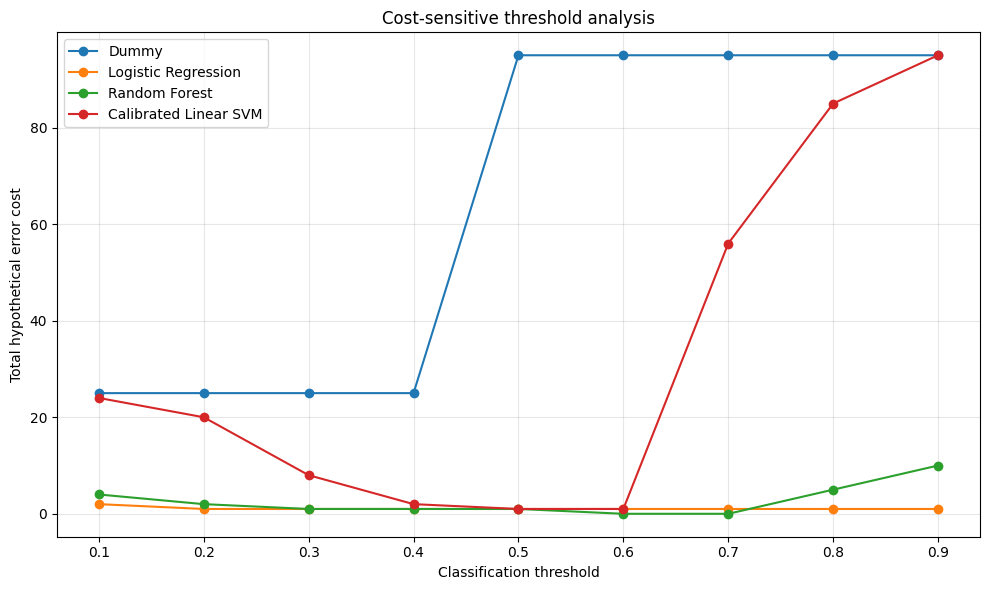

Cost curve saved to: /content/DS-A4-Alzheimers/results/figures/cost_vs_threshold.png


In [261]:
# Cell 53: Plot cost versus classification threshold

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for model_name in models.keys():

    model_data = cost_results[
        cost_results["Model"] == model_name
    ]

    plt.plot(
        model_data["Threshold"],
        model_data["Total error cost"],
        marker="o",
        label=model_name
    )

plt.xlabel("Classification threshold")
plt.ylabel("Total hypothetical error cost")
plt.title("Cost-sensitive threshold analysis")
plt.xticks(np.arange(0.1, 1.0, 0.1))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

cost_curve_path = FIGURES_DIR / "cost_vs_threshold.png"

plt.savefig(
    cost_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Cost curve saved to:", cost_curve_path)

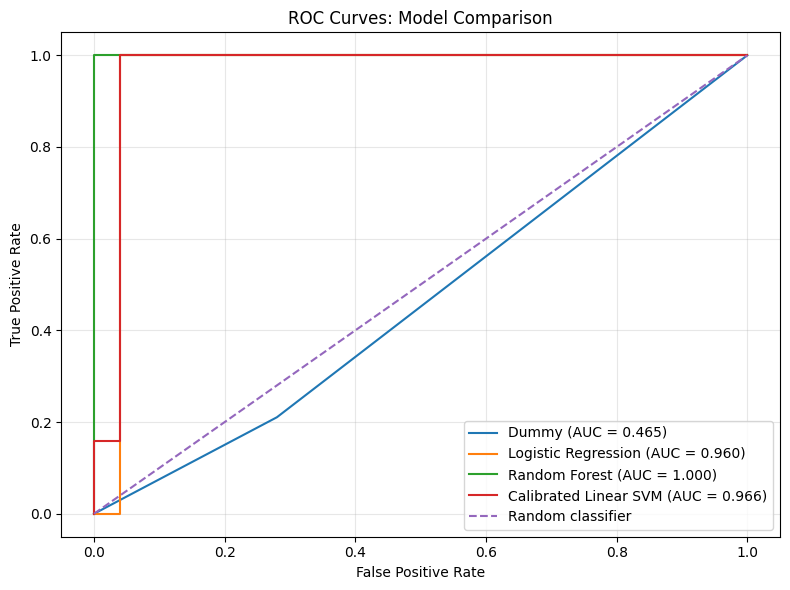

ROC curve saved to: /content/DS-A4-Alzheimers/results/figures/roc_curves.png


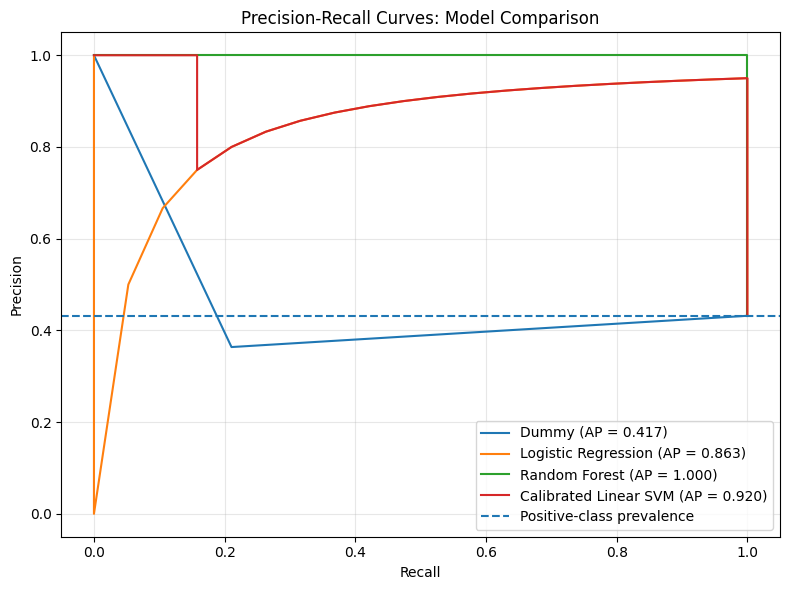

Precision-Recall curve saved to: /content/DS-A4-Alzheimers/results/figures/precision_recall_curves.png


In [262]:
# Cell 54: Plot ROC and Precision-Recall curves

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

y_true = oof_predictions["y_true"].astype(int)

# ROC curve
plt.figure(figsize=(8, 6))

for model_name in models.keys():

    probabilities = oof_predictions[model_name]

    fpr, tpr, _ = roc_curve(y_true, probabilities)
    auc_value = roc_auc_score(y_true, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Model Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

roc_path = FIGURES_DIR / "roc_curves.png"
plt.savefig(roc_path, dpi=300, bbox_inches="tight")
plt.show()

print("ROC curve saved to:", roc_path)


# Precision-Recall curve
plt.figure(figsize=(8, 6))

for model_name in models.keys():

    probabilities = oof_predictions[model_name]

    precision, recall, _ = precision_recall_curve(
        y_true,
        probabilities
    )

    ap_value = average_precision_score(y_true, probabilities)

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP = {ap_value:.3f})"
    )

plt.axhline(
    y_true.mean(),
    linestyle="--",
    label="Positive-class prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves: Model Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

pr_path = FIGURES_DIR / "precision_recall_curves.png"
plt.savefig(pr_path, dpi=300, bbox_inches="tight")
plt.show()

print("Precision-Recall curve saved to:", pr_path)

In [263]:
# Cell 55: Create threshold decision record

threshold_record = """
# DS-A4 Threshold Decision Record

## Project
Alzheimer's disease versus Control classification using GSE48350.

## Decision
The reference classification threshold is 0.50.

This threshold is retained for consistency with the original
model evaluation. It was not selected because it produced
the lowest observed error cost.

## Human review capacity
- Total evaluation samples: 44
- Human review capacity: 44 samples
- Review capacity: 100%

All 44 samples can be reviewed in this exploratory research
setting. Therefore, human review capacity does not impose
a restrictive threshold in this dataset.

The number of samples predicted as AD is not the same as
the number independently reviewed by a human.

## Cost assumptions
- False positive (FP) relative cost: 1
- False negative (FN) relative cost: 5

These are hypothetical relative costs used for sensitivity
analysis. They are not measured clinical or financial costs.

## Sensitivity analysis
Thresholds from 0.1 to 0.9 were evaluated for all four models.
The results are saved in:
results/cost_sensitive_threshold_analysis.csv

The cost curve is saved in:
results/figures/cost_vs_threshold.png

ROC and precision-recall curves are saved in:
results/figures/roc_curves.png
results/figures/precision_recall_curves.png

## Limitations
The threshold analysis uses out-of-fold predictions from
only 44 samples. Selecting a threshold based on the lowest
observed cost in these same samples could produce optimistic
estimates.

The analysis is exploratory and does not establish a
clinically optimal threshold or validate a diagnostic tool.

## Final decision
Retain 0.50 as the provisional reference threshold.
Report alternative thresholds as sensitivity analysis.
Do not claim clinical validity or an optimal threshold.
"""

decision_path = RESULTS_DIR / "threshold_decision_record.md"

with open(decision_path, "w", encoding="utf-8") as file:
    file.write(threshold_record.strip() + "\n")

print("Threshold decision record saved to:", decision_path)
print("Reference threshold: 0.50")
print("Human review capacity:", REVIEW_CAPACITY)
print("Sensitivity thresholds evaluated:", len(thresholds))

Threshold decision record saved to: /content/DS-A4-Alzheimers/results/threshold_decision_record.md
Reference threshold: 0.50
Human review capacity: 44
Sensitivity thresholds evaluated: 9


In [264]:
# Cell 56: Save the evaluation protocol record

from pathlib import Path

# Redefine directories to prevent NameError
PROJECT_DIR = Path("/content/DS-A4-Alzheimers")
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True) # Ensure folder exists

protocol = """
# DS-A4: Frozen Evaluation Protocol Record

## 1. Research question
Can gene-expression profiles distinguish Alzheimer's disease (AD)
from Control samples in the selected hippocampal dataset?

## 2. Dataset and sample selection
- GEO accession: GSE48350
- Platform: GPL570 (Affymetrix)
- Tissue: Hippocampus
- Selected age range: 60 years and older
- Total samples: 44
- AD samples: 19
- Control samples: 25
- Expression features: 54,675 probes before model-based selection

## 3. Outcome definition
- Control = 0
- AD = 1

## 4. Data splitting
- Method: StratifiedKFold cross-validation
- Number of folds: 4
- Shuffle: True
- Random seed: 20261104
- Each model used the same fold assignments.
- Out-of-fold predictions were collected for all 44 samples.

## 5. Models evaluated
1. DummyClassifier with prior strategy (simple baseline).
2. Logistic Regression.
3. Random Forest.
4. Calibrated Linear Support Vector Machine.

## 6. Preprocessing and feature selection
- SelectKBest using the ANOVA F-test.
- 50 probes selected within each training fit.
- StandardScaler used in Logistic Regression and SVM pipelines.
- Random Forest used without feature scaling.
- SVM probability calibration used sigmoid calibration
  with three-fold internal cross-validation.

Feature selection and preprocessing were included in the
model pipelines to avoid fitting them on the outer test folds.

## 7. Evaluation metrics
- Accuracy
- Sensitivity and specificity
- Precision and F1-score
- Balanced accuracy
- ROC-AUC
- Average precision / PR-AUC
- Brier score
- Log loss
- Expected calibration error (ECE)

## 8. Statistical comparisons
- Paired out-of-fold predictions.
- McNemar tests for paired classification outcomes.
- Paired bootstrap comparisons of ROC-AUC and Brier score.
- Bootstrap confidence intervals based on 2,000 resamples.

## 9. Threshold analysis
- Reference threshold: 0.50.
- Sensitivity thresholds: 0.1 to 0.9.
- Hypothetical FP cost: 1.
- Hypothetical FN cost: 5.
- Human review capacity: 44 samples.

The cost assumptions are illustrative, not measured clinical costs.
The reference threshold was retained for consistency rather than
selected retrospectively from the lowest observed error cost.

## 10. Reproducibility
- Random seed: 20261104
- Dataset file: GSE48350_series_matrix.txt.gz
- Dataset SHA-256:
  4bb36e0cf50306a96aea853de5f70d5ab63345238997bed8c9b5b290ced58fef

## 11. Limitations and deviations
- Only 44 samples were evaluated.
- All AD samples belonged to GSM prefix group GSM117,
  while all Control samples belonged to GSM300.
- This perfect association raises a potential source or cohort
  confounding concern. Its cause cannot be established from
  the available metadata alone.
- The evaluation is internal cross-validation, not external
  validation.
- Subgroup estimates are based on small sample sizes.
- The protocol is documented after analysis; it should not be
  represented as prospectively registered before results were seen.
- No clinical diagnostic validity is established.
"""

protocol_path = RESULTS_DIR / "frozen_evaluation_protocol.md"

import os
with open(protocol_path, "w", encoding="utf-8") as file:
    file.write(protocol.strip() + os.linesep)

print("Evaluation protocol saved to:", protocol_path)
print("Dataset: GSE48350")
print("Samples: 44 (19 AD, 25 Control)")
print("Cross-validation: 4-fold StratifiedKFold")
print("Models: See model comparison section in this notebook.")
print("Random seed: Recorded in the analysis configuration.")

Evaluation protocol saved to: /content/DS-A4-Alzheimers/results/frozen_evaluation_protocol.md
Dataset: GSE48350
Samples: 44 (19 AD, 25 Control)
Cross-validation: 4-fold StratifiedKFold
Models: See model comparison section in this notebook.
Random seed: Recorded in the analysis configuration.


In [265]:
from pathlib import Path

RESULTS_DIR = Path("/content/DS-A4-Alzheimers/results")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Results directory:", RESULTS_DIR)
print("Directory exists:", RESULTS_DIR.exists())

Results directory: /content/DS-A4-Alzheimers/results
Directory exists: True


In [266]:
# Cell 57: Create AI-use disclosure log

ai_log = """
# DS-A4 AI-use Log

## AI tool
ChatGPT (OpenAI)

## Tasks supported by AI
- Explanation of statistical and machine-learning concepts.
- Guidance on debugging Python and pandas errors.
- Suggestions for model evaluation and visualization.
- Guidance on interpreting ROC, PR, calibration and cost results.
- Assistance in organizing documentation and reproducibility records.

## Work independently performed and verified
- Dataset selection and preprocessing were executed in Google Colab.
- Model training and cross-validation were executed by the student.
- Predictions, metrics, statistical comparisons and figures were
  generated from the actual dataset.
- Outputs were inspected after running notebook cells.

## Advice accepted
- Use identical stratified folds for paired model comparisons.
- Keep feature selection inside the training pipeline.
- Examine threshold sensitivity rather than selecting a threshold
  solely from the lowest observed cost.
- Report dataset limitations and the potential source-confounding issue.

## Advice requiring correction or qualification
- The predicted-positive sample count was distinguished from
  the number of samples actually reviewed by a human.
- Hypothetical error costs were identified as illustrative,
  not measured clinical or financial costs.
- The evaluation protocol was documented after analysis and
  was not described as prospectively registered.

## Independent verification
The student ran the provided code in Google Colab and checked
the resulting outputs and saved files.

## Responsibility
The student remains responsible for the code, analysis,
interpretation, scientific conclusions and final submission.
"""

ai_log_path = RESULTS_DIR / "AI_use_log.md"

with open(ai_log_path, "w", encoding="utf-8") as file:
    file.write(ai_log.strip() + "\n")

print("AI-use log saved to:", ai_log_path)

AI-use log saved to: /content/DS-A4-Alzheimers/results/AI_use_log.md


In [267]:
# Cell 58: Record software environment

import sys
import platform
import pandas as pd
import numpy as np
import sklearn
import matplotlib
from pathlib import Path

# Define project results directory
PROJECT_DIR = Path("/content/DS-A4-Alzheimers")
RESULTS_DIR = PROJECT_DIR / "results"

# Ensure results directory exists
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Record actual software environment
environment_info = {
    "Python": sys.version,
    "Platform": platform.platform(),
    "Pandas": pd.__version__,
    "NumPy": np.__version__,
    "Scikit-learn": sklearn.__version__,
    "Matplotlib": matplotlib.__version__,
    "Random seed": 20261104
}

environment_df = pd.DataFrame(
    list(environment_info.items()),
    columns=["Component", "Version"]
)

environment_path = RESULTS_DIR / "environment_versions.csv"

environment_df.to_csv(environment_path, index=False)

print(environment_df.to_string(index=False))
print("\nEnvironment record saved to:", environment_path)

   Component                                            Version
      Python 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
    Platform               Linux-6.6.159+-x86_64-with-glibc2.39
      Pandas                                              2.2.3
       NumPy                                              2.4.6
Scikit-learn                                              1.6.1
  Matplotlib                                             3.10.0
 Random seed                                           20261104

Environment record saved to: /content/DS-A4-Alzheimers/results/environment_versions.csv


In [268]:
# Cell 59: Check saved project files

from pathlib import Path

PROJECT_DIR = Path("/content/DS-A4-Alzheimers")
RESULTS_DIR = PROJECT_DIR / "results"
DATA_DIR = PROJECT_DIR / "data"
FIGURES_DIR = RESULTS_DIR / "figures"

print("PROJECT FILE CHECK")
print("=" * 50)

for folder in [DATA_DIR, RESULTS_DIR, FIGURES_DIR]:

    print(f"\nFolder: {folder}")

    if folder.exists():
        files = sorted(folder.iterdir())

        if files:
            for file in files:
                if file.is_file():
                    print(f"  [FOUND] {file.name}")
        else:
            print("  Folder is empty")
    else:
        print("  [MISSING] Folder does not exist")

PROJECT FILE CHECK

Folder: /content/DS-A4-Alzheimers/data
  [FOUND] GSE48350_selected_expression.csv
  [FOUND] GSE48350_selected_metadata.csv
  [FOUND] GSE48350_series_matrix.txt.gz

Folder: /content/DS-A4-Alzheimers/results
  [FOUND] AI_use_log.md
  [FOUND] age_group_performance.csv
  [FOUND] combined_model_performance.csv
  [FOUND] cost_sensitive_threshold_analysis.csv
  [FOUND] diagnosis_GSM_prefix_audit.csv
  [FOUND] environment_versions.csv
  [FOUND] fold_assignments.csv
  [FOUND] frozen_evaluation_protocol.md
  [FOUND] gender_group_performance.csv
  [FOUND] misclassified_samples.csv
  [FOUND] oof_predictions.csv
  [FOUND] paired_bootstrap_comparisons.csv
  [FOUND] subgroup_performance.csv
  [FOUND] threshold_decision_record.md

Folder: /content/DS-A4-Alzheimers/results/figures
  [FOUND] calibration_curves.png
  [FOUND] cost_vs_threshold.png
  [FOUND] precision_recall_curves.png
  [FOUND] roc_curves.png


In [269]:
# Cell 60: Inspect current Colab workspace

from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nContents of /content:")

for item in sorted(Path("/content").iterdir()):
    print(item.name, "(folder)" if item.is_dir() else "(file)")

print("\nChecking Google Drive mount:")

drive_path = Path("/content/drive/MyDrive")

if drive_path.exists():
    print("Google Drive is mounted.")
else:
    print("Google Drive is not currently mounted.")

Current working directory:
/content

Contents of /content:
.config (folder)
DS-A4-Alzheimers (folder)
sample_data (folder)

Checking Google Drive mount:
Google Drive is not currently mounted.


In [270]:
# Cell 61: Inspect all files inside the project

from pathlib import Path

PROJECT_DIR = Path("/content/DS-A4-Alzheimers")

print("Complete project directory:")
print(PROJECT_DIR)

print("\nAll existing files and folders:")
print("=" * 55)

for item in sorted(PROJECT_DIR.rglob("*")):
    relative_path = item.relative_to(PROJECT_DIR)

    if item.is_dir():
        print("[FOLDER]", relative_path)
    else:
        print("[FILE]", relative_path)

print("\nInspection completed.")

Complete project directory:
/content/DS-A4-Alzheimers

All existing files and folders:
[FOLDER] data
[FILE] data/GSE48350_selected_expression.csv
[FILE] data/GSE48350_selected_metadata.csv
[FILE] data/GSE48350_series_matrix.txt.gz
[FOLDER] results
[FILE] results/AI_use_log.md
[FILE] results/age_group_performance.csv
[FILE] results/combined_model_performance.csv
[FILE] results/cost_sensitive_threshold_analysis.csv
[FILE] results/diagnosis_GSM_prefix_audit.csv
[FILE] results/environment_versions.csv
[FOLDER] results/figures
[FILE] results/figures/calibration_curves.png
[FILE] results/figures/cost_vs_threshold.png
[FILE] results/figures/precision_recall_curves.png
[FILE] results/figures/roc_curves.png
[FILE] results/fold_assignments.csv
[FILE] results/frozen_evaluation_protocol.md
[FILE] results/gender_group_performance.csv
[FILE] results/misclassified_samples.csv
[FILE] results/oof_predictions.csv
[FILE] results/paired_bootstrap_comparisons.csv
[FILE] results/subgroup_performance.csv
[FI

In [271]:
# Cell 62: Restore project directory structure

from pathlib import Path

PROJECT_DIR = Path("/content/DS-A4-Alzheimers")
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

for folder in [DATA_DIR, RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directories restored successfully.")

print("Project:", PROJECT_DIR)
print("Data:", DATA_DIR)
print("Results:", RESULTS_DIR)
print("Figures:", FIGURES_DIR)

Project directories restored successfully.
Project: /content/DS-A4-Alzheimers
Data: /content/DS-A4-Alzheimers/data
Results: /content/DS-A4-Alzheimers/results
Figures: /content/DS-A4-Alzheimers/results/figures


In [272]:
# Cell 63: Download original GEO dataset

import urllib.request
import hashlib

geo_url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE48nnn/GSE48350/matrix/"
    "GSE48350_series_matrix.txt.gz"
)

geo_path = DATA_DIR / "GSE48350_series_matrix.txt.gz"

if not geo_path.exists():
    print("Downloading GEO dataset...")
    urllib.request.urlretrieve(geo_url, geo_path)
else:
    print("Dataset already exists.")

sha256_hash = hashlib.sha256()

with open(geo_path, "rb") as file:
    for chunk in iter(lambda: file.read(1024 * 1024), b""):
        sha256_hash.update(chunk)

print("\nDataset saved to:", geo_path)
print("File size:", geo_path.stat().st_size, "bytes")
print("SHA-256:", sha256_hash.hexdigest())

Dataset already exists.

Dataset saved to: /content/DS-A4-Alzheimers/data/GSE48350_series_matrix.txt.gz
File size: 60194969 bytes
SHA-256: 4bb36e0cf50306a96aea853de5f70d5ab63345238997bed8c9b5b290ced58fef
